# Convert a TIFF stack or Suite2p movie to GIF/MP4

This notebook loads either a multi-page TIFF or a registered Suite2p binary movie, applies an optional temporal rolling average, converts intensities to displayable 8-bit frames, and exports a GIF and/or MP4 video. For this dataset, Suite2p channel 1 (`data.bin`) is used as the functional channel.

## 1. Install dependencies (once)

Uncomment and run the line below if these packages are not already installed in your environment.

In [22]:
# %pip install tifffile imageio imageio-ffmpeg pillow matplotlib numpy

## 2. Imports and settings

Set `SOURCE_PATH` to either a TIFF file, a Suite2p results directory, or a Suite2p plane directory. In auto mode, a directory is treated as Suite2p output. Channel 1 (`data.bin`) is selected explicitly. The defaults render a 60-second excerpt, which is much faster than processing an entire recording.

In [23]:
from pathlib import Path

import imageio.v2 as imageio
import matplotlib.pyplot as plt
import numpy as np
import tifffile
from IPython.display import Image, Video, display

# ---- Edit these settings ----
SOURCE_PATH = Path('/Volumes/behrens/meg/3x3_field_magnitude_bandit/derivatives/cohort-01/sub-03_id-MY_71_R/ses-177_date-20260624/funcimg/destriped_distortion_uncorrected/suite2p/')
SOURCE_TYPE = "auto"  # "auto", "tiff", or "suite2p"
SUITE2P_PLANE = 0
SUITE2P_CHANNEL = 1  # Functional channel for this dataset; reads data.bin
OUTPUT_DIR = SOURCE_PATH.parent if SOURCE_PATH.suffix else SOURCE_PATH
FPS = 7.52
START_SECONDS = 10*60+30
DURATION_SECONDS = 180  # Set to None only when you really want the entire recording
ROLLING_WINDOW = 5  # About 0.66 seconds at 7.52 fps; set to 1 for no smoothing
FRAME_STEP = 1  # Keep every result so playback timing matches the recording
CONTRAST_MODE = "percentile"  # "percentile" or "manual"
LOW_PERCENTILE = 10.0  # Raise this to push more background toward black
HIGH_PERCENTILE = 99.5  # Lower this (for example, 99.0) for more contrast
MANUAL_BLACK = 0  # Used only when CONTRAST_MODE = "manual"
MANUAL_WHITE = 1000  # Used only when CONTRAST_MODE = "manual"
GAMMA = 1.2  # Above 1 darkens background/midtones; 1 is linear
EXPORT_GIF = True  # GIF is slow and large; enable it only when needed
EXPORT_MP4 = True

OUTPUT_STEM = SOURCE_PATH.stem if SOURCE_PATH.suffix else f"{SOURCE_PATH.name}_plane{SUITE2P_PLANE}"
GIF_PATH = OUTPUT_DIR / f"{OUTPUT_STEM}_rolling{ROLLING_WINDOW}.gif"
MP4_PATH = OUTPUT_DIR / f"{OUTPUT_STEM}_rolling{ROLLING_WINDOW}.mp4"

## 3. Inspect and load the source movie

TIFF stacks are loaded normally. Suite2p's registered `data.bin` is memory-mapped instead of copied into RAM; its frame dimensions come from `ops.npy`. You can point to the Suite2p root, `suite2p/`, or a specific `planeN/` directory.

In [24]:
if not SOURCE_PATH.exists():
    raise FileNotFoundError(f"Source not found: {SOURCE_PATH}")
if ROLLING_WINDOW < 1:
    raise ValueError("ROLLING_WINDOW must be at least 1")
if FRAME_STEP < 1:
    raise ValueError("FRAME_STEP must be at least 1")
if FPS <= 0:
    raise ValueError("FPS must be greater than 0")

def find_suite2p_plane(path, plane_number=0):
    candidates = [
        path,
        path / f"plane{plane_number}",
        path / "suite2p" / f"plane{plane_number}",
    ]
    for candidate in candidates:
        if (candidate / "ops.npy").exists():
            return candidate
    raise FileNotFoundError(
        f"Could not find plane{plane_number}/ops.npy under {path}. "
        "Point SOURCE_PATH to the Suite2p root, suite2p folder, or plane folder."
    )


def load_suite2p_movie(path, plane_number=0, channel="functional"):
    plane_dir = find_suite2p_plane(path, plane_number)
    ops = np.load(plane_dir / "ops.npy", allow_pickle=True).item()
    height, width = int(ops["Ly"]), int(ops["Lx"])
    functional_channel = int(ops.get("functional_chan", 1))
    selected_channel = functional_channel if channel == "functional" else int(channel)
    if selected_channel not in (1, 2):
        raise ValueError("Suite2p channel must be 'functional', 1, or 2")
    binary_name = "data.bin" if selected_channel == 1 else "data_chan2.bin"
    binary_path = plane_dir / binary_name

    # ops['reg_file'] may contain an old absolute path after data are moved,
    # so the binary beside ops.npy is preferred.
    if not binary_path.exists():
        ops_path_key = "reg_file" if selected_channel == 1 else "reg_file_chan2"
        recorded_path = Path(str(ops.get(ops_path_key, "")))
        if recorded_path.exists():
            binary_path = recorded_path
    if not binary_path.exists():
        raise FileNotFoundError(f"Registered Suite2p movie not found: {binary_path}")

    dtype = np.dtype(np.int16)  # Suite2p registered binaries use signed 16-bit pixels
    bytes_per_frame = height * width * dtype.itemsize
    file_bytes = binary_path.stat().st_size
    if file_bytes % bytes_per_frame:
        raise ValueError(
            f"{binary_path} size is incompatible with Ly={height}, Lx={width}, dtype={dtype}."
        )
    frame_count = file_bytes // bytes_per_frame
    movie = np.memmap(binary_path, dtype=dtype, mode="r", shape=(frame_count, height, width))
    print(f"Suite2p plane: {plane_dir}")
    print(f"Functional channel in ops.npy: {functional_channel}; selected channel: {selected_channel}")
    print(f"Registered binary: {binary_path}")
    print(f"ops.npy reports nframes={ops.get('nframes', 'unknown')}; file contains {frame_count:,}")
    return movie


source_type = SOURCE_TYPE.lower()
if source_type == "auto":
    source_type = "suite2p" if SOURCE_PATH.is_dir() else "tiff"

if source_type == "suite2p":
    if SUITE2P_CHANNEL not in ("functional", 1, 2):
        raise ValueError("SUITE2P_CHANNEL must be 'functional', 1, or 2")
    stack = load_suite2p_movie(SOURCE_PATH, SUITE2P_PLANE, SUITE2P_CHANNEL)
elif source_type == "tiff":
    with tifffile.TiffFile(SOURCE_PATH) as tif:
        print(f"TIFF pages: {len(tif.pages):,}")
        print(f"Series shape: {tif.series[0].shape}")
        print(f"Series dtype: {tif.series[0].dtype}")
        print(f"Axes (when available): {tif.series[0].axes}")
    stack = np.squeeze(tifffile.imread(SOURCE_PATH))
else:
    raise ValueError("SOURCE_TYPE must be 'auto', 'tiff', or 'suite2p'")

print(f"Movie shape: {stack.shape}; dtype: {stack.dtype}")

if stack.ndim == 2:
    stack = stack[None, ...]
elif stack.ndim not in (3, 4):
    raise ValueError(
        f"Expected a 2D image, 3D grayscale stack, or 4D RGB stack; got {stack.shape}. "
        "Select or reshape the time axis before continuing."
    )

start_frame = max(0, round(START_SECONDS * FPS))
stop_frame = len(stack) if DURATION_SECONDS is None else min(
    len(stack), start_frame + round(DURATION_SECONDS * FPS)
)
if start_frame >= len(stack) or stop_frame <= start_frame:
    raise ValueError("The requested time range contains no frames.")
stack = stack[start_frame:stop_frame]
SOURCE_START_FRAME = start_frame
print(
    f"Selected source frames {start_frame:,}–{stop_frame - 1:,} "
    f"({len(stack) / FPS:.1f} seconds)"
)

if ROLLING_WINDOW > len(stack):
    raise ValueError(
        f"ROLLING_WINDOW ({ROLLING_WINDOW}) exceeds the number of frames ({len(stack)})."
    )

Suite2p plane: /Volumes/behrens/meg/3x3_field_magnitude_bandit/derivatives/cohort-01/sub-03_id-MY_71_R/ses-177_date-20260624/funcimg/destriped_distortion_uncorrected/suite2p/plane0
Functional channel in ops.npy: 2; selected channel: 1
Registered binary: /Volumes/behrens/meg/3x3_field_magnitude_bandit/derivatives/cohort-01/sub-03_id-MY_71_R/ses-177_date-20260624/funcimg/destriped_distortion_uncorrected/suite2p/plane0/data.bin
ops.npy reports nframes=14001; file contains 14,001
Movie shape: (14001, 512, 512); dtype: int16
Selected source frames 4,738–6,091 (180.1 seconds)


## 4. Apply the rolling average

Each output frame is the mean of the current frame and the preceding `ROLLING_WINDOW - 1` frames. With a window of 500, the first result represents source frames 0–499. The running-sum implementation uses much less temporary memory than constructing a full cumulative-sum stack.

In [25]:
def rolling_mean_frames(data, window=500, step=1):
    data = np.asarray(data)
    output_count = 1 + (len(data) - window) // step
    output = np.empty((output_count, *data.shape[1:]), dtype=np.float32)
    running_sum = np.zeros(data.shape[1:], dtype=np.float32)
    output_index = 0

    for frame_index, frame in enumerate(data):
        running_sum += frame
        if frame_index >= window:
            running_sum -= data[frame_index - window]

        window_end = frame_index - (window - 1)
        if frame_index >= window - 1 and window_end % step == 0:
            output[output_index] = running_sum / window
            output_index += 1

    return output

frames = rolling_mean_frames(stack, ROLLING_WINDOW, FRAME_STEP)
print(
    f"Created {len(frames):,} rolling-average frames "
    f"(window={ROLLING_WINDOW}, step={FRAME_STEP})"
)

Created 1,350 rolling-average frames (window=5, step=1)


## 5. Convert frames to 8-bit

GIF and ordinary video players expect display-ready 8-bit pixels. Contrast is calculated once for the entire selected interval and then held fixed across all frames, so real intensity changes remain visible without auto-contrast flicker. Percentile mode is convenient; manual mode gives identical black/white levels across different recordings. Gamma below 1 brightens dim midtones without changing the selected endpoints.

In [26]:
def to_uint8_movie(
    data,
    contrast_mode="percentile",
    low_percentile=10.0,
    high_percentile=99.5,
    manual_black=0,
    manual_white=1000,
    gamma=1.0,
):
    data = np.asarray(data)
    is_rgb = data.ndim == 4 and data.shape[-1] in (3, 4)

    if is_rgb:
        data = data[..., :3]
        if data.dtype == np.uint8:
            return data

    # Limit the percentile calculation to about 10 million sampled values.
    sample_step = max(1, int(np.ceil(data.size / 10_000_000)))
    sample = data.reshape(-1)[::sample_step]
    finite_sample = sample[np.isfinite(sample)]
    if finite_sample.size == 0:
        raise ValueError("The TIFF contains no finite pixel values.")

    if contrast_mode == "percentile":
        low, high = np.percentile(finite_sample, [low_percentile, high_percentile])
    elif contrast_mode == "manual":
        low, high = float(manual_black), float(manual_white)
    else:
        raise ValueError("CONTRAST_MODE must be 'percentile' or 'manual'")
    if high <= low:
        raise ValueError(f"Invalid intensity range: low={low}, high={high}")
    if gamma <= 0:
        raise ValueError("GAMMA must be greater than zero")

    scaled = np.nan_to_num((data.astype(np.float32) - low) / (high - low))
    scaled = np.clip(scaled, 0, 1) ** gamma
    clipped_low = 100 * np.mean(finite_sample <= low)
    clipped_high = 100 * np.mean(finite_sample >= high)
    print(f"Display range: {low:.3g} to {high:.3g}; gamma: {gamma:g}")
    print(f"Sample clipped: {clipped_low:.2f}% black, {clipped_high:.2f}% white")
    return np.round(scaled * 255).astype(np.uint8)

movie = to_uint8_movie(
    frames,
    contrast_mode=CONTRAST_MODE,
    low_percentile=LOW_PERCENTILE,
    high_percentile=HIGH_PERCENTILE,
    manual_black=MANUAL_BLACK,
    manual_white=MANUAL_WHITE,
    gamma=GAMMA,
)
print(f"Output array: {movie.shape}; dtype: {movie.dtype}")

Display range: -48.6 to 421; gamma: 1.2
Sample clipped: 10.14% black, 0.50% white
Output array: (1350, 512, 512); dtype: uint8


## 6. Preview representative frames

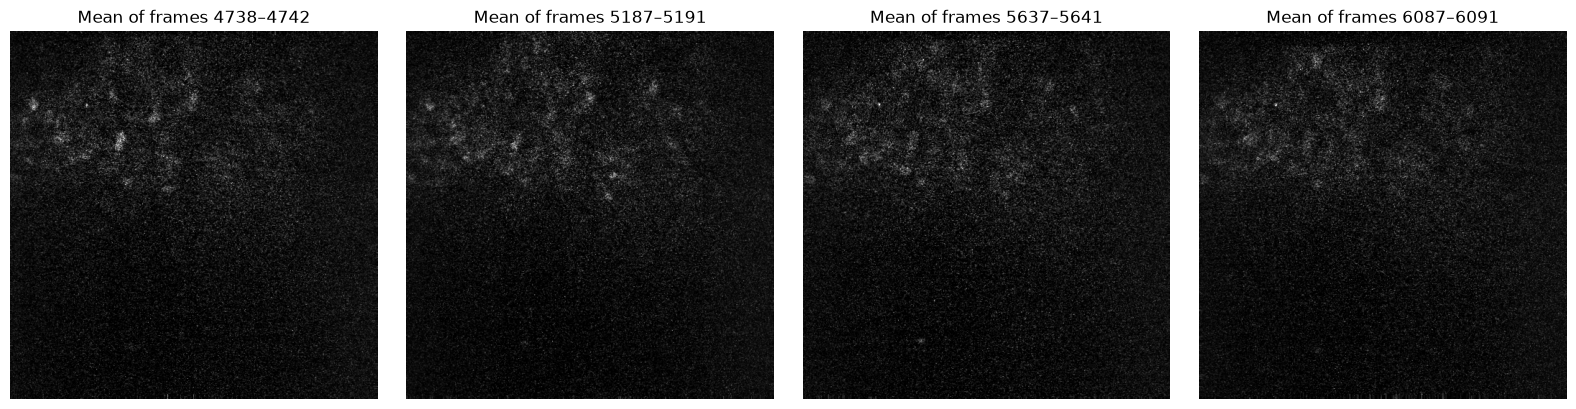

In [27]:
preview_indices = np.unique(np.linspace(0, len(movie) - 1, min(4, len(movie)), dtype=int))
fig, axes = plt.subplots(1, len(preview_indices), figsize=(4 * len(preview_indices), 4), squeeze=False)

for ax, index in zip(axes[0], preview_indices):
    if movie.ndim == 3:
        ax.imshow(movie[index], cmap="gray", vmin=0, vmax=255)
    else:
        ax.imshow(movie[index])
    source_end = SOURCE_START_FRAME + (ROLLING_WINDOW - 1) + index * FRAME_STEP
    source_start = source_end - ROLLING_WINDOW + 1
    ax.set_title(f"Mean of frames {source_start}–{source_end}")
    ax.axis("off")

plt.tight_layout()
plt.show()

## 7. Export GIF

GIF is easy to share but is usually larger and lower quality than MP4. `loop=0` makes it repeat forever.

In [ ]:
if EXPORT_GIF:
    OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
    imageio.mimsave(GIF_PATH, movie, duration=1 / FPS, loop=0)
    print(f"Saved GIF: {GIF_PATH}")
    display(Image(filename=str(GIF_PATH)))

Saved GIF: /Volumes/behrens/meg/3x3_field_magnitude_bandit/derivatives/cohort-01/sub-03_id-MY_71_R/ses-177_date-20260624/funcimg/destriped_distortion_uncorrected/suite2p/suite2p_plane0_rolling5.gif


## 8. Export MP4

H.264 video requires even frame dimensions in many players. The helper below pads an odd final row or column without cropping your data.

In [ ]:
def pad_to_even(data):
    height, width = data.shape[1:3]
    pad_height = height % 2
    pad_width = width % 2
    if not (pad_height or pad_width):
        return data
    padding = [(0, 0), (0, pad_height), (0, pad_width)]
    if data.ndim == 4:
        padding.append((0, 0))
    return np.pad(data, padding, mode="edge")

if EXPORT_MP4:
    OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
    mp4_movie = pad_to_even(movie)
    imageio.mimsave(
        MP4_PATH,
        mp4_movie,
        fps=FPS,
        codec="libx264",
        quality=8,
        macro_block_size=None,
        ffmpeg_params=["-pix_fmt", "yuv420p"],
    )
    print(f"Saved MP4: {MP4_PATH}")
    display(Video(str(MP4_PATH), embed=True))

## Troubleshooting

- **Make the background darker (Fiji-like):** raise `LOW_PERCENTILE` (try 10, 20, or 30) and/or raise `GAMMA` (try 1.2–1.5).
- **Recover faint cells:** lower `LOW_PERCENTILE` or move `GAMMA` back toward 1.
- **Bright cells are clipped:** raise `HIGH_PERCENTILE` toward 99.9 or 100.
- **Match contrast between recordings:** use `CONTRAST_MODE = "manual"` and reuse the same `MANUAL_BLACK` and `MANUAL_WHITE` values.
- **Avoid false blinking:** do not calculate percentiles separately for every frame. This notebook deliberately uses one global mapping for the selected interval.
- **The video is too fast or slow:** change `FPS`.
- **The smoothing is too strong:** reduce `ROLLING_WINDOW`; set it to 1 for no temporal averaging. At 7.52 fps, five frames span about 0.66 seconds.
- **It is taking too long:** keep `DURATION_SECONDS` around 30–60 seconds, leave `EXPORT_GIF = False`, and export MP4. GIF encoding is substantially slower and produces larger files.
- **Render a different interval:** change `START_SECONDS`. Set `DURATION_SECONDS = None` only to process the complete recording.
- **The output is too large:** increase `FRAME_STEP` or export only MP4. If you increase `FRAME_STEP`, set playback `FPS` to `7.52 / FRAME_STEP` to preserve real-time speed.
- **Suite2p binary is missing:** enable Suite2p's registered-movie saving, or point to a result that still contains `planeN/data.bin`.
- **Functional channel selection:** this dataset uses `SUITE2P_CHANNEL = 1`, which reads `data.bin`. Channel 2 would read `data_chan2.bin`.
- **The frame axis is last:** before selecting frames, use `stack = np.moveaxis(stack, -1, 0)`.
- **The TIFF has channel or Z dimensions:** select the desired channel/Z plane before the conversion cell, so the resulting array is `(frames, height, width)`.